In [1]:
from IPython.display import Image, display
import numpy as np
import reddemcee

np.random.seed(1234)

# Quickstart

We will start with a simple 2D gaussian shell evaluation:
- Widely used in the literature (vg, dynesty and multinest papers, as well as Vousden and Lartillot&Philippe 2009)
- It is analytically tractable.

## 2D Gaussian Shell
The likelihood is given by:

$$ p(\vec{\theta}) = \sum_{i=1}^n \frac{1}{\sqrt{2\pi w^2}} \exp{\left( -\frac{(|\vec{\theta} - \vec{c_i}| - r)^2}{2w^2} \right)} $$

where $n$ are the number of dimensions, $r$ corresponds to the radius, $w$ the width and $\vec{c_i}$ to the constant vectors describing the centre of the peaks.

The likelihood looks like [this](https://github.com/ReddTea/reddemcee/blob/main/docs/img/2dglike.png).


## Constants
In the following section we will define the relevant constants to the problem


In [2]:
ndim_ = 2  # n dimensions
r_ = 2.  # radius
w_ = 0.1  # width
hard_limit = 6  # hard search boundary

limits_ = [-hard_limit,  hard_limit]
c1_ = np.zeros(ndim_)
c1_[0] = -3.5
c2_ = np.zeros(ndim_)
c2_[0] = 3.5
const_ = np.log(1. / np.sqrt(2. * np.pi * w_**2))

## Probability functions
Reddemcee needs the likelihood and prior separately, so we will define these functions:

In [3]:
def logcirc(theta, c):
    # log-likelihood of a single shell
    d = np.sqrt(np.sum((theta - c)**2, axis=-1))  # |theta - c|
    return const_ - (d - r_)**2 / (2. * w_**2)


def loglike(theta):
    # log-likelihood of two shells
    return np.logaddexp(logcirc(theta, c1_), logcirc(theta, c2_))


def logprior(theta):
    # prior for our parameters
    lp = 0.
    for i in range(ndim_):
        if  theta[i] <= limits_[0] or limits_[1] <= theta[i]:
            return -np.inf
    return lp

## Setup
Here we write the sampler initial conditions:

In [4]:
setup = [4, 100, 200, 2]
ntemps, nwalkers, nsweeps, nsteps = setup
p0 = np.random.uniform(limits_[0], limits_[1], [ntemps, nwalkers, ndim_])

### Initiating the sampler

In [5]:
sampler = reddemcee.PTSampler(nwalkers, ndim_, loglike, logprior,
                              ntemps=ntemps)
    
silent = sampler.run_mcmc(p0, nsweeps, nsteps, progress=True)

100%|██████████| 1600/1600 [00:01<00:00, 833.49it/s]


## Retrieving Results
Some of the quantities you would like to see the most are the samples, likelihoods and the posteriors:

In [6]:
ch = sampler.get_chain(flat=True)
ll = sampler.get_log_like(flat=True)
pt = sampler.get_log_prob(flat=True)

## Some visualization
We can display a couple of informative plots:

In [7]:
import matplotlib.pyplot as pl
from matplotlib.ticker import MaxNLocator

def display_samples(sampler, temp=0):
    nd = sampler.ndim
    fig, axes = pl.subplots(1, nd, figsize=(8, 2*nd))
    
    samples = sampler.get_chain(flat=True)
    
    for i in range(len(axes)):
        axes[i].hist(samples[temp][:, i], 100, histtype="step", lw=1)
        axes[i].set_xlabel(fr"$\theta_{i}$")
        axes[i].set_ylabel(fr"$N \theta_{i}$")
    pl.gca().set_yticks([])
    fig.suptitle('Samples')
    
def display_chains(sampler, dens=False, temp=0):
    nd = sampler.ndim
    fig, axes = pl.subplots(nd, 1, sharex=True, figsize=(8, nd*3))
    samples = sampler.get_chain(flat=False)
    for i in range(len(axes)):
        if dens:
             axes[i].plot(samples[temp][:, :, i], marker='o', alpha=0.75, lw=0)
        else:
             axes[i].plot(samples[temp][:, :, i], alpha=0.75, lw=1)
        
        axes[i].yaxis.set_major_locator(MaxNLocator(5))
        axes[i].set_ylabel(fr"$\theta_{i}$")
        
    fig.suptitle('Chains')
    fig.supxlabel('N step')

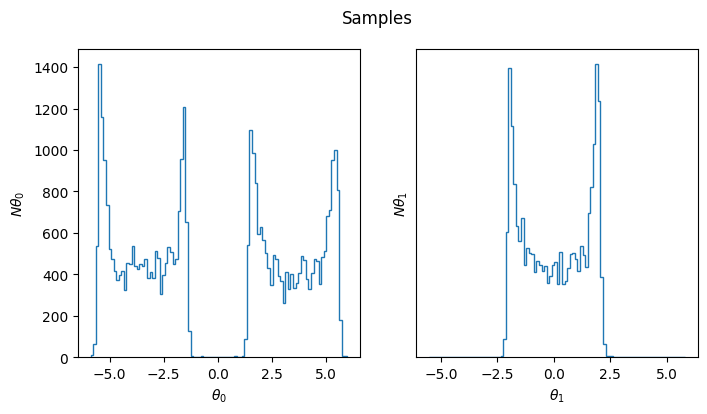

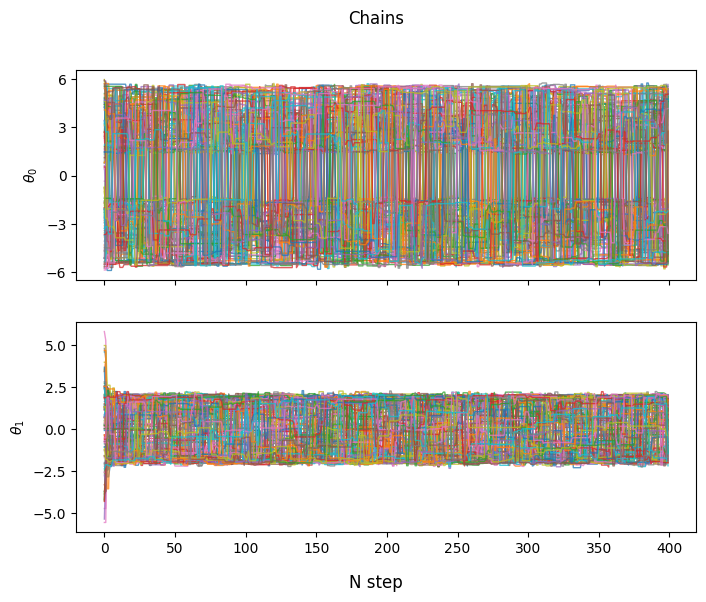

In [8]:
display_samples(sampler)
display_chains(sampler, dens=False)

Just for fun, we will make a re-run with emcee, to compare how the walkers mix between maximas:

In [9]:
import emcee

def logpost(theta):
    return loglike(theta) + logprior(theta)

setup = [100, 1600]
nwalkers, nsteps = setup
p0 = list(np.random.uniform(limits_[0], limits_[1], [nwalkers, ndim_]))

In [10]:
sampler_emcee = emcee.EnsembleSampler(nwalkers, ndim_, logpost)
    
silent_emcee = sampler_emcee.run_mcmc(p0, nsteps, progress=True)

100%|██████████| 1600/1600 [00:02<00:00, 712.21it/s]


And we display the samples:

Text(0.5, 0.01, 'Step')

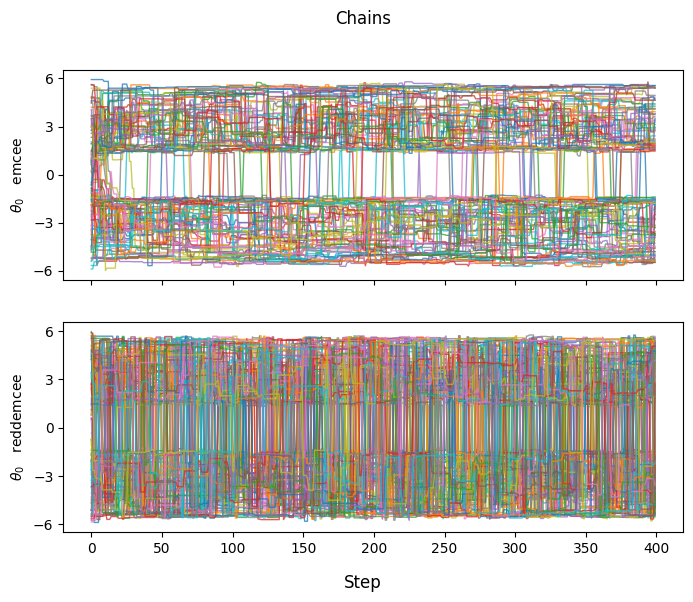

In [11]:
dens=False
fig, axes = pl.subplots(ndim_, 1, sharex=True, figsize=(8, ndim_*3))
samples_emcee = sampler_emcee.get_chain()

# emcee
if dens:
    axes[0].plot(samples_emcee[:400, :, 0], marker='o', alpha=0.75, lw=0)
else:
    axes[0].plot(samples_emcee[:400, :, 0], alpha=0.75, lw=1)
        
axes[0].yaxis.set_major_locator(MaxNLocator(5))
axes[0].set_ylabel(r"$\theta_0 \quad \text{emcee}$")


samples_r = sampler.get_chain(flat=False)
if dens:
    axes[1].plot(samples_r[0][:, :, 0], marker='o', alpha=0.75, lw=0)
else:
    axes[1].plot(samples_r[0][:, :, 0], alpha=0.75, lw=1)
        
axes[1].yaxis.set_major_locator(MaxNLocator(5))
axes[1].set_ylabel(r"$\theta_0 \quad \text{reddemcee}$")

fig.suptitle('Chains')
fig.supxlabel('Step')

Text(0.5, 0.01, 'Step')

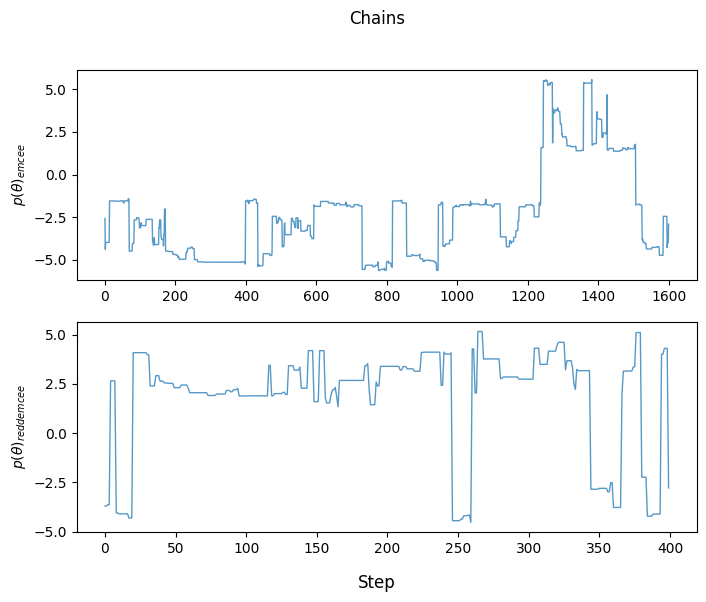

In [12]:
dens=False
fig, axes = pl.subplots(ndim_, 1,
                        #sharex=True,
                        figsize=(8, ndim_*3))
samples = sampler_emcee.get_chain()

# emcee
if dens:
    axes[0].plot(samples[:, :1, 0], marker='o', alpha=0.75, lw=0)
else:
    axes[0].plot(samples[:, :1, 0], alpha=0.75, lw=1)
        
axes[0].yaxis.set_major_locator(MaxNLocator(5))
axes[0].set_ylabel(r"$p(\theta)_{emcee}$")


samples_r = sampler.get_chain(flat=False)
if dens:
    axes[1].plot(samples_r[0][:, :1, 0], marker='o', alpha=0.75, lw=0)
else:
    axes[1].plot(samples_r[0][:, :1, 0], alpha=0.75, lw=1)
        
axes[1].yaxis.set_major_locator(MaxNLocator(5))
axes[1].set_ylabel(r"$p(\theta)_{reddemcee}$")

fig.suptitle('Chains')
fig.supxlabel('Step')

We see that individual walkers spend more time stuck in their own high probability region, meaning reddemcee manages better mixing for this problem.